# Part 2b. Hierarchical clustering

Each review starts as its own cluster. The closest pair is merged until one cluster remains. The dendrogram height is the linkage distance of that merge.

- **Average:** mean pairwise distance between the two clusters.
- **Complete:** distance between the farthest pair of points.
- **Ward:** increase in within-cluster sum of squares if the two clusters were merged.

The tree is cut with `fcluster` for \(K = 2, \ldots, 8\). Silhouette picks the cut. Cophenetic correlation scores the whole tree against the original pairwise distances. The same six standardised ratings are used.

## Setup, cleaning, and scaling

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
if not (ROOT / "data" / "airlines_reviews.csv").exists():
    ROOT = Path(r"C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning")

DATA_PATH = ROOT / "data" / "airlines_reviews.csv"
FIG = ROOT / "figures" / "hierarchical"
OUT = ROOT / "outputs" / "hierarchical"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

RATING_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages",
    "Inflight Entertainment", "Value For Money", "Overall Rating",
]
SERVICE_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages", "Inflight Entertainment",
]
RANDOM_STATE = 42


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()


def silhouette_safe(X, labels):
    # Silhouette on non-noise points. NaN when a partition is not valid.
    labels = np.asarray(labels)
    mask = labels != -1
    y = labels[mask]
    if len(y) < 3 or len(np.unique(y)) < 2:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    if counts.min() < 2:
        return np.nan
    return float(silhouette_score(X[mask], y, n_jobs=-1))


print("Question folder:", FIG.parent.name + "/" + FIG.name)
print("Data file:", DATA_PATH)

Question folder: figures/hierarchical
Data file: C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning\data\airlines_reviews.csv


In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
text_cols = [col for col in df.columns if pd.api.types.is_string_dtype(df[col])]
for col in text_cols:
    df[col] = df[col].str.replace("\xa0", " ", regex=False).str.strip()

verified_map = {
    "True": "True", "False": "False", "*Unverified*": "False", "NotVerified": "False",
}
n_verified_fixed = int((~df["Verified"].isin(["True", "False"])).sum())
df["Verified"] = df["Verified"].map(verified_map).fillna("False")

ife = df["Inflight Entertainment"]
n_ife_zero = int((ife == 0).sum())
ife_median = float(ife[ife > 0].median())
df.loc[ife == 0, "Inflight Entertainment"] = ife_median

n_dups = int(df["Reviews"].duplicated().sum())
df = df.drop_duplicates(subset=["Reviews"]).reset_index(drop=True)

df["Month Flown Date"] = pd.to_datetime(df["Month Flown"], format="%B %Y")
df["Year Flown"] = df["Month Flown Date"].dt.year
df["Year Bin"] = pd.cut(
    df["Year Flown"],
    bins=[2012, 2016, 2019, 2021, 2025],
    labels=["2013-2016", "2017-2019", "2020-2021", "2022-2024"],
).astype(str)
df["Review Length"] = df["Reviews"].str.len()

print(f"Rows before cleaning: {len(raw):,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Verified flags corrected: {n_verified_fixed}")
print(f"Inflight Entertainment zeros imputed with median {ife_median:.0f}: {n_ife_zero}")
print(f"Duplicate reviews removed: {n_dups}")

Rows before cleaning: 8,100
Rows after cleaning:  8,098
Verified flags corrected: 3
Inflight Entertainment zeros imputed with median 4: 1
Duplicate reviews removed: 2


In [3]:
def scale_frame(frame, cols):
    scaler = StandardScaler()
    return scaler.fit_transform(frame[cols]), scaler


X_main, scaler_main = scale_frame(df, RATING_COLS)
X_no_overall, _ = scale_frame(df, [c for c in RATING_COLS if c != "Overall Rating"])
X_service, _ = scale_frame(df, SERVICE_COLS)

scale_table = pd.DataFrame({
    "feature": RATING_COLS,
    "mean": scaler_main.mean_,
    "std": scaler_main.scale_,
})
display(scale_table.round(3))
scale_table.round(6).to_csv(OUT / "standard_scaler_parameters.csv", index=False)

example_raw = df.loc[0, RATING_COLS].to_numpy(dtype=float)
example_z = (example_raw - scaler_main.mean_) / scaler_main.scale_
example_check = scaler_main.transform(df.loc[[0], RATING_COLS])[0]
worked = pd.DataFrame({
    "feature": RATING_COLS,
    "raw_x": example_raw,
    "mean": scaler_main.mean_,
    "std": scaler_main.scale_,
    "z_manual": example_z,
    "z_scaler": example_check,
})
print("Worked standardisation for review 0. z = (x - mean) / std")
display(worked.round(4))
print("Max gap between manual z and StandardScaler:", float(np.max(np.abs(example_z - example_check))))

encoder = OneHotEncoder(sparse_output=False, dtype=np.float64)
cat_cols = ["Airline", "Class", "Type of Traveller", "Year Bin"]
X_cat = encoder.fit_transform(df[cat_cols])
X_mixed = np.hstack([X_main, X_cat])
pca_mixed = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_mixed_pca = pca_mixed.fit_transform(X_mixed)

pca_viz = PCA(n_components=2, random_state=RANDOM_STATE)
XY = pca_viz.fit_transform(X_main)
loadings = pd.DataFrame(pca_viz.components_.T, index=RATING_COLS, columns=["PC1", "PC2"])
print("PCA loadings on the 6 standardised ratings:")
display(loadings.round(3))
print(
    f"PC1 + PC2 explain {pca_viz.explained_variance_ratio_.sum():.1%} of rating variance. "
    f"Mixed-feature PCA kept {X_mixed_pca.shape[1]} components "
    f"({pca_mixed.explained_variance_ratio_.sum():.1%} variance)."
)
loadings.round(4).to_csv(OUT / "pca_loadings.csv")

,feature,mean,std
0,Seat Comfort,3.415,1.397
1,Staff Service,3.570,1.527
2,Food & Beverages,3.384,1.455
3,Inflight Entertainment,3.637,1.309
4,Value For Money,3.149,1.589
5,Overall Rating,5.632,3.523


Worked standardisation for review 0. z = (x - mean) / std


,feature,raw_x,mean,std,z_manual,z_scaler
0,Seat Comfort,4.0,3.4149,1.3969,0.4188,0.4188
1,Staff Service,4.0,3.5699,1.5273,0.2816,0.2816
2,Food & Beverages,4.0,3.3842,1.4554,0.4231,0.4231
3,Inflight Entertainment,4.0,3.6371,1.3089,0.2773,0.2773
4,Value For Money,4.0,3.1486,1.5893,0.5357,0.5357
5,Overall Rating,9.0,5.6324,3.5233,0.9558,0.9558


Max gap between manual z and StandardScaler: 0.0
PCA loadings on the 6 standardised ratings:


,PC1,PC2
Seat Comfort,0.292,0.368
Staff Service,0.309,0.318
Food & Beverages,0.249,0.473
Inflight Entertainment,0.228,0.514
Value For Money,0.591,-0.379
Overall Rating,0.597,-0.363


PC1 + PC2 explain 55.3% of rating variance. Mixed-feature PCA kept 13 components (91.5% variance).


In [4]:
def name_clusters(frame, label_col, score_col="Overall Rating"):
    # Name groups from low to high mean overall rating. Noise (-1) stays Noise.
    means = frame.loc[frame[label_col] != -1].groupby(label_col)[score_col].mean().sort_values()
    labels = list(means.index)
    if len(labels) == 2:
        pretty = ["Low satisfaction", "High satisfaction"]
    elif len(labels) == 3:
        pretty = ["Low satisfaction", "Mixed satisfaction", "High satisfaction"]
    else:
        pretty = [f"Segment {i} (low to high)" for i in range(1, len(labels) + 1)]
    mapping = {lab: pretty[i] for i, lab in enumerate(labels)}
    if (frame[label_col] == -1).any():
        mapping[-1] = "Noise"
    return mapping


def profile_clusters(frame, label_col):
    rows = []
    for lab, g in frame.groupby(label_col):
        row = {
            "cluster": lab,
            "n": len(g),
            "pct": 100 * len(g) / len(frame),
            "recommend_rate": g["Recommended"].str.lower().eq("yes").mean(),
        }
        for col in RATING_COLS:
            row[col] = g[col].mean()
        rows.append(row)
    out = pd.DataFrame(rows)
    out["name"] = out["cluster"].map(name_clusters(frame, label_col))
    return out.sort_values("Overall Rating")

## Linkages, dendrogram, and cut

complete linkage requested K=2, but fcluster returned 1 cluster(s). Tied merge heights make that cut undefined, so silhouette is left blank.


Cophenetic correlation (how well the tree preserves pairwise distances):


,cophenetic
ward,0.5515
complete,0.5502
average,0.6180


Silhouette of each flat cut:


,ward,complete,average
2,0.2469,NaN,0.2471
3,0.1987,0.1700,0.1858
4,0.1576,0.1387,0.1712
5,0.1530,0.1309,0.1411
6,0.1323,0.1212,0.1372
7,0.1326,0.1156,0.1397
8,0.1381,0.1227,0.1316


Selected cut: average linkage, K = 2, silhouette 0.2471.
Hierarchical profile:


,cluster,n,pct,recommend_rate,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,name
0,1,3707,45.777,0.086,3.216,3.175,3.143,3.462,1.691,2.282,Low satisfaction
1,2,4391,54.223,0.903,3.583,3.903,3.588,3.785,4.379,8.461,High satisfaction


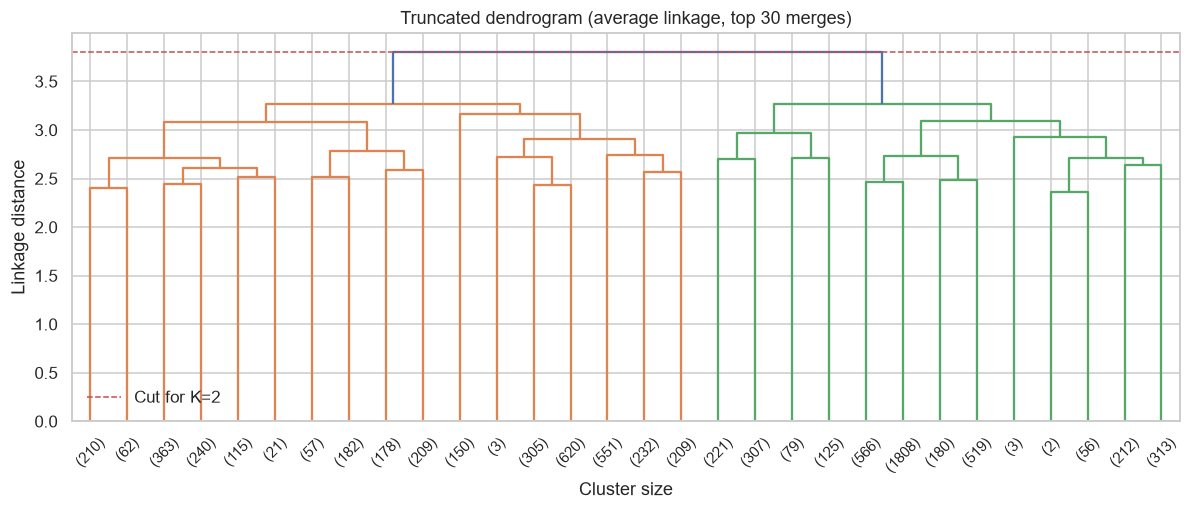

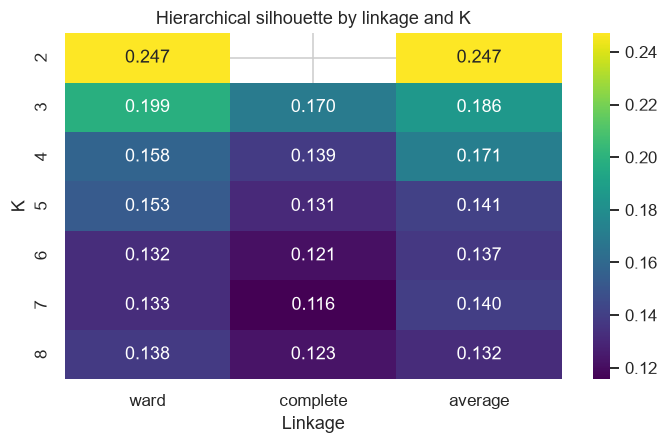

In [5]:
linkages = {}
cophenetic_scores = {}
distance_condensed = pdist(X_main, metric="euclidean")
for method in ["ward", "complete", "average"]:
    Z = linkage(X_main, method=method, metric="euclidean")
    linkages[method] = Z
    cophenetic_scores[method] = float(cophenet(Z, distance_condensed)[0])

sil_link = pd.DataFrame(index=range(2, 9), columns=["ward", "complete", "average"], dtype=float)
for method, Z in linkages.items():
    for k in sil_link.index:
        labels = fcluster(Z, t=k, criterion="maxclust")
        n_found = len(np.unique(labels))
        if n_found != k:
            sil_link.loc[k, method] = np.nan
            print(
                f"{method} linkage requested K={k}, but fcluster returned {n_found} "
                "cluster(s). Tied merge heights make that cut undefined, so silhouette is left blank."
            )
        else:
            sil_link.loc[k, method] = silhouette_safe(X_main, labels)

print("Cophenetic correlation (how well the tree preserves pairwise distances):")
display(pd.Series(cophenetic_scores, name="cophenetic").round(4).to_frame())
print("Silhouette of each flat cut:")
display(sil_link.round(4))
sil_link.to_csv(OUT / "hierarchical_silhouette.csv")

best_pos = np.unravel_index(np.nanargmax(sil_link.to_numpy()), sil_link.shape)
hier_k = int(sil_link.index[best_pos[0]])
hier_method = str(sil_link.columns[best_pos[1]])
hier_sil = float(sil_link.loc[hier_k, hier_method])
print(f"Selected cut: {hier_method} linkage, K = {hier_k}, silhouette {hier_sil:.4f}.")

Z_best = linkages[hier_method]
df["hierarchical"] = fcluster(Z_best, t=hier_k, criterion="maxclust")
h_profile = profile_clusters(df, "hierarchical")
h_names = name_clusters(df, "hierarchical")
df["hierarchical_name"] = df["hierarchical"].map(h_names)
print("Hierarchical profile:")
display(h_profile.round(3))
h_profile.round(3).to_csv(OUT / "hierarchical_profile.csv", index=False)

color_threshold = Z_best[-(hier_k - 1), 2]
fig, ax = plt.subplots(figsize=(11, 4.8))
dendrogram(
    Z_best, truncate_mode="lastp", p=30, color_threshold=color_threshold,
    above_threshold_color="#4C72B0", ax=ax,
)
ax.axhline(color_threshold, color="#C44E52", ls="--", lw=1, label=f"Cut for K={hier_k}")
ax.set_title(f"Truncated dendrogram ({hier_method} linkage, top 30 merges)")
ax.set_xlabel("Cluster size")
ax.set_ylabel("Linkage distance")
ax.legend(frameon=False)
save_fig(fig, "dendrogram.png")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.heatmap(sil_link.astype(float), annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_title("Hierarchical silhouette by linkage and K")
ax.set_xlabel("Linkage")
ax.set_ylabel("K")
save_fig(fig, "linkage_silhouette.png")

## Part 2b answer

The selected linkage and \(K\) are printed above the dendrogram. A blank silhouette means `fcluster` could not form that many clusters because merge heights were tied. Cophenetic correlation and the flat-cut silhouette answer different questions: one scores the tree, the other scores a single partition.